# imports

In [2]:
import pandas as pd
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
from scipy.stats import shapiro
import numpy as np
from scipy.stats import mannwhitneyu, ks_2samp

# define functions

In [178]:
def data_by_cid(df, cid):
    output = df[df["cid"] == cid]

    return output

def hourly_resampling(df):
    df_set_index = df.set_index("cycle_start_time")

    df_set_index = df_set_index.sort_index()

    df_resampled = df_set_index.resample("h").agg({
        "plan_name": "first",  
        "vehicle_count": "sum",    
        "ds": "mean"
    }).reset_index()

    df_resampled = df_resampled.sort_values(by="cycle_start_time", ascending=True)

    df_dropped_NA = df_resampled.dropna()

    return df_dropped_NA

def split_AB_cases(df, split_datetime):
    case_A = df[df["cycle_start_time"] <= split_datetime]
    case_B = df[df["cycle_start_time"] > split_datetime]

    return case_A, case_B

def test_normality(df):
    res = {}

    shapiro_statistic, p_value = shapiro(df)

    res["shapiro_statistic"] = shapiro_statistic
    res["p_value"] = p_value

    return res

def parametric_statistics(case_A, case_B):
    results = {}

    # calculate variance assuming case_A and case_B is pandas dataframe colum
    variance_A = case_A.var()
    variance_B = case_B.var()

    if variance_A != variance_B:
        t_statistic, p_value = ttest_ind(case_A, case_B, alternative="two-sided", equal_var=False)
        results["t_statistic"] = t_statistic
        results["p_value"] = p_value
        results["equal_var"] = False
    else:
        t_statistic, p_value = ttest_ind(case_A, case_B, alternative="two-sided", equal_var=True)
        results["t_statistic"] = t_statistic
        results["p_value"] = p_value
        results["equal_var"] = True

    return results

def non_parametric_statistics(case_A, case_B):
    res = {}

    u_statistic, u_p_value = mannwhitneyu(case_A, case_B, alternative="two-sided")
    ks_statistic, ks_p_value = ks_2samp(case_A, case_B, alternative="two-sided")
    
    res["u_statistic"] = u_statistic
    res["u_p_value"] = u_p_value
    res["ks_statistic"] = ks_statistic
    res["ks_p_value"] = ks_p_value
    
    return res

# load all data for a particular cluster

In [4]:
data_source_path = "C:/Users/Rahman/Downloads/dev.csv"
all_junctions = pd.read_csv(data_source_path)

all_junctions["cycle_start_time"] = pd.to_datetime(
    all_junctions["cycle_start_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="raise"
)

In [5]:
all_junctions

,cycle_plan_pk,cid,plan_name,cycle_length,cycle_start_time,stage_name,exec_green,detector_name,vehicle_count,ds,queue
0,5988537,943,PLN03,172,2024-11-26 11:32:43,STG01,77,V3,31,28,11
1,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V3,25,28,13
2,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V4,15,13,7
3,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V1,19,40,24
4,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V2,16,34,22
...,...,...,...,...,...,...,...,...,...,...,...
842206,5939329,943,PLN06,108,2024-11-25 22:14:54,STG03,13,V6,13,49,36
842207,5939589,935,PLN06,100,2024-11-25 22:19:17,STG02,51,V1,12,29,15
842208,5939589,935,PLN06,100,2024-11-25 22:19:17,STG02,51,V2,10,29,18
842209,5939589,935,PLN06,100,2024-11-25 22:19:17,STG02,51,V3,4,13,5


In [6]:
all_junctions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842211 entries, 0 to 842210
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   cycle_plan_pk     842211 non-null  int64         
 1   cid               842211 non-null  int64         
 2   plan_name         842211 non-null  object        
 3   cycle_length      842211 non-null  int64         
 4   cycle_start_time  842161 non-null  datetime64[ns]
 5   stage_name        842211 non-null  object        
 6   exec_green        842211 non-null  int64         
 7   detector_name     842211 non-null  object        
 8   vehicle_count     842211 non-null  int64         
 9   ds                842211 non-null  int64         
 10  queue             842211 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(3)
memory usage: 70.7+ MB


# analysis for 935

## filter data for 935 only

In [7]:
df_935 = data_by_cid(all_junctions, 943)

In [8]:
df_935

,cycle_plan_pk,cid,plan_name,cycle_length,cycle_start_time,stage_name,exec_green,detector_name,vehicle_count,ds,queue
0,5988537,943,PLN03,172,2024-11-26 11:32:43,STG01,77,V3,31,28,11
1,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V3,25,28,13
2,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V4,15,13,7
3,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V1,19,40,24
4,5989143,943,PLN03,169,2024-11-26 11:44:23,STG01,74,V2,16,34,22
...,...,...,...,...,...,...,...,...,...,...,...
842202,5979702,943,PLN02,172,2024-11-26 08:32:16,STG01,84,V3,6,33,20
842203,5979702,943,PLN02,172,2024-11-26 08:32:16,STG01,84,V4,10,22,13
842204,5979702,943,PLN02,172,2024-11-26 08:32:16,STG01,84,V1,9,49,28
842205,5979702,943,PLN02,172,2024-11-26 08:32:16,STG01,84,V2,8,43,23


In [12]:
df_935.info()

<class 'pandas.core.frame.DataFrame'>
Index: 348841 entries, 0 to 842206
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   cycle_plan_pk     348841 non-null  int64         
 1   cid               348841 non-null  int64         
 2   plan_name         348841 non-null  object        
 3   cycle_length      348841 non-null  int64         
 4   cycle_start_time  348816 non-null  datetime64[ns]
 5   stage_name        348841 non-null  object        
 6   exec_green        348841 non-null  int64         
 7   detector_name     348841 non-null  object        
 8   vehicle_count     348841 non-null  int64         
 9   ds                348841 non-null  int64         
 10  queue             348841 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(3)
memory usage: 31.9+ MB


## resample data hourly

In [17]:
hourly_935 = hourly_resampling(df_935)
hourly_935 = hourly_935.drop(columns=["vehicle_count"])

In [18]:
hourly_935

,cycle_start_time,plan_name,ds
0,2024-10-06 21:00:00,PLN03,29.625000
84,2024-10-10 09:00:00,PLNAP,17.000000
90,2024-10-10 15:00:00,PLN02,41.250000
96,2024-10-10 21:00:00,PLNPP,32.625000
98,2024-10-10 23:00:00,PLN01,15.000000
...,...,...,...
1400,2024-12-04 05:00:00,PLN01,6.939306
1401,2024-12-04 06:00:00,PLN06,20.828729
1402,2024-12-04 07:00:00,PLN02,42.594771
1403,2024-12-04 08:00:00,PLN02,44.699346


In [19]:
hourly_935.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1305 entries, 0 to 1404
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   cycle_start_time  1305 non-null   datetime64[ns]
 1   plan_name         1305 non-null   object        
 2   ds                1305 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 40.8+ KB


## define split datetime for A-B case

In [20]:
split_datetime = pd.Timestamp("2024-11-12 23:00:00")

## split into A-B time range 

In [38]:
case_A_935, case_B_935 = split_AB_cases(hourly_935, split_datetime)

In [89]:
case_A_935

,cycle_start_time,plan_name,ds
0,2024-10-06 21:00:00,PLN03,29.625000
84,2024-10-10 09:00:00,PLNAP,17.000000
90,2024-10-10 15:00:00,PLN02,41.250000
96,2024-10-10 21:00:00,PLNPP,32.625000
98,2024-10-10 23:00:00,PLN01,15.000000
...,...,...,...
886,2024-11-12 19:00:00,PLN04,45.818841
887,2024-11-12 20:00:00,PLN04,35.131944
888,2024-11-12 21:00:00,PLN04,30.396450
889,2024-11-12 22:00:00,PLN06,23.336323


In [90]:
case_B_935

,cycle_start_time,plan_name,ds
891,2024-11-13 00:00:00,PLN01,12.846561
892,2024-11-13 01:00:00,PLN01,7.297030
893,2024-11-13 02:00:00,PLN01,3.844828
894,2024-11-13 03:00:00,PLN01,3.473118
895,2024-11-13 04:00:00,PLN01,2.473239
...,...,...,...
1400,2024-12-04 05:00:00,PLN01,6.939306
1401,2024-12-04 06:00:00,PLN06,20.828729
1402,2024-12-04 07:00:00,PLN02,42.594771
1403,2024-12-04 08:00:00,PLN02,44.699346


## segregate A/B split by hour of day

In [91]:
case_A_935["hour"] = case_A_935["cycle_start_time"].dt.hour

C:\Users\Rahman\AppData\Local\Temp\ipykernel_36952\1540228492.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  case_A_935["hour"] = case_A_935["cycle_start_time"].dt.hour


In [95]:
case_B_935["hour"] = case_B_935["cycle_start_time"].dt.hour

C:\Users\Rahman\AppData\Local\Temp\ipykernel_36952\666853521.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  case_B_935["hour"] = case_B_935["cycle_start_time"].dt.hour


In [92]:
case_A_935

,cycle_start_time,plan_name,ds,hour
0,2024-10-06 21:00:00,PLN03,29.625000,21
84,2024-10-10 09:00:00,PLNAP,17.000000,9
90,2024-10-10 15:00:00,PLN02,41.250000,15
96,2024-10-10 21:00:00,PLNPP,32.625000,21
98,2024-10-10 23:00:00,PLN01,15.000000,23
...,...,...,...,...
886,2024-11-12 19:00:00,PLN04,45.818841,19
887,2024-11-12 20:00:00,PLN04,35.131944,20
888,2024-11-12 21:00:00,PLN04,30.396450,21
889,2024-11-12 22:00:00,PLN06,23.336323,22


In [96]:
case_B_935

,cycle_start_time,plan_name,ds,hour
891,2024-11-13 00:00:00,PLN01,12.846561,0
892,2024-11-13 01:00:00,PLN01,7.297030,1
893,2024-11-13 02:00:00,PLN01,3.844828,2
894,2024-11-13 03:00:00,PLN01,3.473118,3
895,2024-11-13 04:00:00,PLN01,2.473239,4
...,...,...,...,...
1400,2024-12-04 05:00:00,PLN01,6.939306,5
1401,2024-12-04 06:00:00,PLN06,20.828729,6
1402,2024-12-04 07:00:00,PLN02,42.594771,7
1403,2024-12-04 08:00:00,PLN02,44.699346,8


### AM peak (0600HRS - 0900HRS)

In [93]:
case_A_AM = case_A_935[(case_A_935["hour"] >= 6) & (case_A_935["hour"] <= 9)]

In [94]:
case_A_AM

,cycle_start_time,plan_name,ds,hour
84,2024-10-10 09:00:00,PLNAP,17.000000,9
105,2024-10-11 06:00:00,PLN01,22.246377,6
106,2024-10-11 07:00:00,PLNAP,38.518797,7
107,2024-10-11 08:00:00,PLNAP,42.430556,8
108,2024-10-11 09:00:00,PLNAP,37.218310,9
...,...,...,...,...
852,2024-11-11 09:00:00,PLN02,37.365672,9
873,2024-11-12 06:00:00,PLN06,22.386076,6
874,2024-11-12 07:00:00,PLN02,43.459259,7
875,2024-11-12 08:00:00,PLN02,45.071429,8


In [97]:
case_B_AM = case_B_935[(case_B_935["hour"] >= 6) & (case_B_935["hour"] <= 9)]

In [98]:
case_B_AM

,cycle_start_time,plan_name,ds,hour
897,2024-11-13 06:00:00,PLN06,24.535484,6
898,2024-11-13 07:00:00,PLN02,43.710938,7
899,2024-11-13 08:00:00,PLN02,45.593333,8
900,2024-11-13 09:00:00,PLN02,44.895522,9
921,2024-11-14 06:00:00,PLN06,23.743750,6
...,...,...,...,...
1380,2024-12-03 09:00:00,PLN02,41.192771,9
1401,2024-12-04 06:00:00,PLN06,20.828729,6
1402,2024-12-04 07:00:00,PLN02,42.594771,7
1403,2024-12-04 08:00:00,PLN02,44.699346,8


basic stats and distribution

In [166]:
case_A_AM.describe()

,cycle_start_time,ds,hour
count,133,133.000000,133.000000
mean,2024-10-27 04:26:36.992481024,30.950849,7.511278
min,2024-10-10 09:00:00,6.952880,6.000000
25%,2024-10-19 06:00:00,22.619355,7.000000
50%,2024-10-27 07:00:00,33.532374,8.000000
75%,2024-11-04 08:00:00,40.221429,9.000000
max,2024-11-12 09:00:00,47.414815,9.000000
std,NaN,10.250495,1.125574


In [167]:
case_B_AM.describe()

,cycle_start_time,ds,hour
count,87,87.000000,87.000000
mean,2024-11-23 21:16:33.103448064,33.829172,7.482759
min,2024-11-13 06:00:00,9.433476,6.000000
25%,2024-11-18 08:30:00,24.074505,6.500000
50%,2024-11-24 06:00:00,39.436090,7.000000
75%,2024-11-29 07:30:00,42.696515,8.000000
max,2024-12-04 09:00:00,46.121429,9.000000
std,NaN,10.562325,1.119199


distribution plots

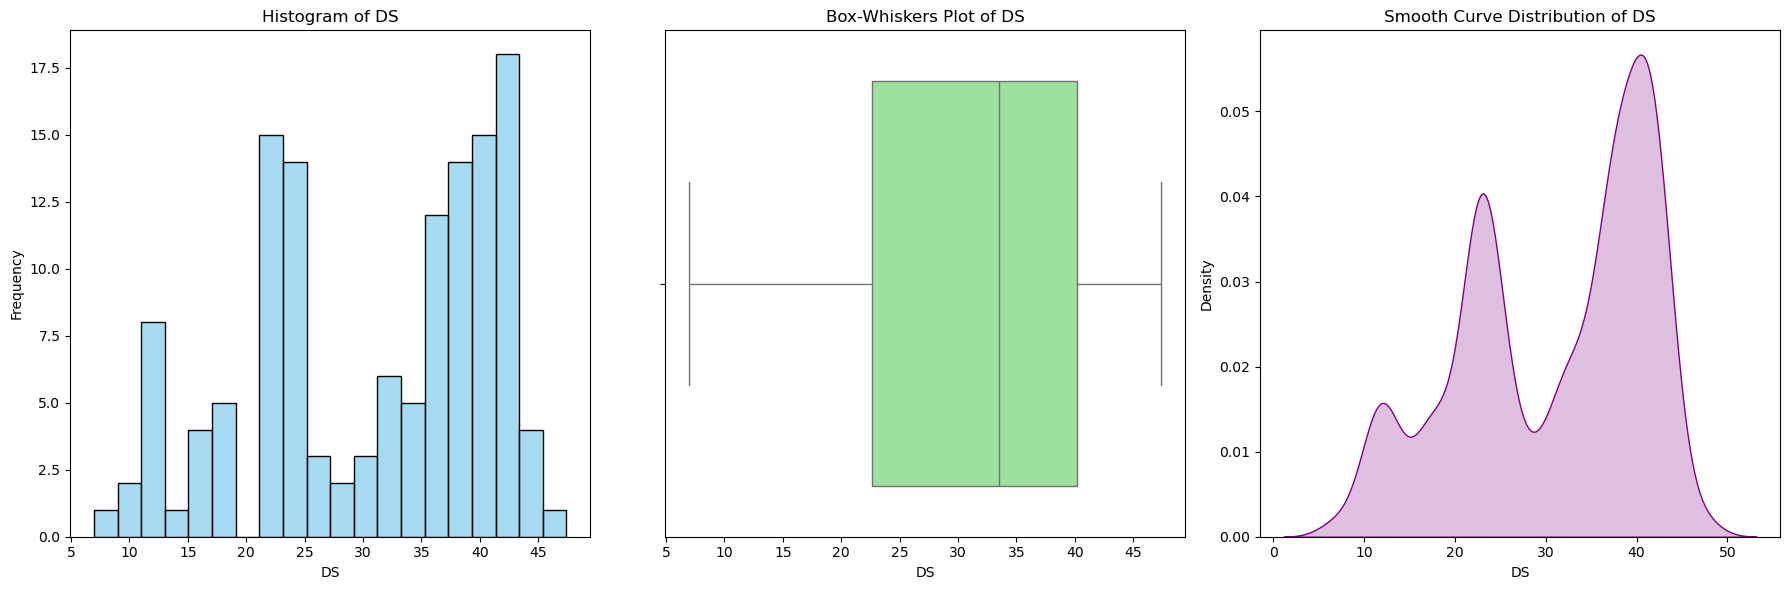

In [168]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Extract "ds" column
ds_values = case_A_AM["ds"]

# Create a figure with multiple subplots
plt.figure(figsize=(18, 6))

# Histogram
plt.subplot(1, 3, 1)
sns.histplot(ds_values, bins=20, kde=False, color="skyblue", edgecolor="black")
plt.title("Histogram of DS")
plt.xlabel("DS")
plt.ylabel("Frequency")

# Box-Whiskers Plot
plt.subplot(1, 3, 2)
sns.boxplot(x=ds_values, color="lightgreen")
plt.title("Box-Whiskers Plot of DS")
plt.xlabel("DS")

# Smooth Curve Distribution (Kernel Density Estimate)
plt.subplot(1, 3, 3)
sns.kdeplot(ds_values, fill=True, color="purple", bw_adjust=0.5)
plt.title("Smooth Curve Distribution of DS")
plt.xlabel("DS")
plt.ylabel("Density")

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

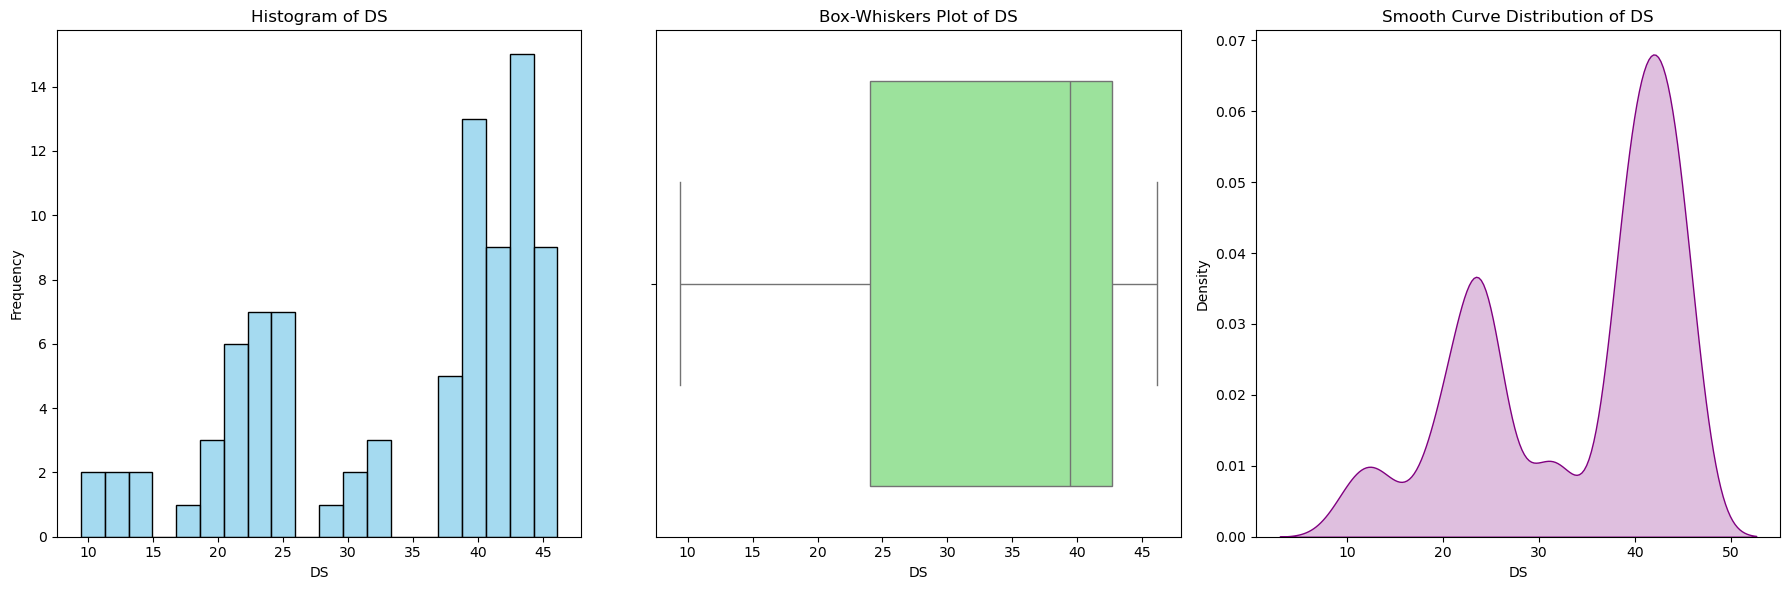

In [169]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Extract "ds" column
ds_values = case_B_AM["ds"]

# Create a figure with multiple subplots
plt.figure(figsize=(18, 6))

# Histogram
plt.subplot(1, 3, 1)
sns.histplot(ds_values, bins=20, kde=False, color="skyblue", edgecolor="black")
plt.title("Histogram of DS")
plt.xlabel("DS")
plt.ylabel("Frequency")

# Box-Whiskers Plot
plt.subplot(1, 3, 2)
sns.boxplot(x=ds_values, color="lightgreen")
plt.title("Box-Whiskers Plot of DS")
plt.xlabel("DS")

# Smooth Curve Distribution (Kernel Density Estimate)
plt.subplot(1, 3, 3)
sns.kdeplot(ds_values, fill=True, color="purple", bw_adjust=0.5)
plt.title("Smooth Curve Distribution of DS")
plt.xlabel("DS")
plt.ylabel("Density")

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

In [174]:
test_normality(case_A_AM["ds"])

{'shapiro_statistic': 0.916994345804329, 'p_value': 5.375356447168105e-07}

In [175]:
test_normality(case_B_AM["ds"])

{'shapiro_statistic': 0.8683642103228908, 'p_value': 2.901848656999449e-07}

When deciding between **parametric** (e.g., t-tests, Welch's t-test) and **non-parametric** tests (e.g., Mann-Whitney U, Kolmogorov-Smirnov), certain assumptions about the data and sample size should guide the choice. Here's an overview:

---

### **1. Parametric Tests (e.g., t-test, Welch's t-test)**

#### **Key Assumptions**:
1. **Normality**: 
   - Data in each group should be approximately normally distributed. 
   - This can be checked with tests like Shapiro-Wilk or visualizations like histograms or Q-Q plots.
   - Welch's t-test is slightly more robust to violations of normality, especially for larger sample sizes.

2. **Homogeneity of Variances** (t-test only):
   - Variance in both groups should be similar (homoscedasticity).
   - Can be tested with Levene's test or Bartlett's test.
   - Welch's t-test is used when variances are unequal (heteroscedasticity).

3. **Independence**:
   - Observations within and across groups must be independent.
   - This assumption applies to both t-tests and Welch's t-test.

4. **Sample Size**:
   - Works well with **smaller sample sizes** if normality is met (e.g., \( n > 30 \)).
   - For larger sample sizes (\( n > 50 \)), the central limit theorem makes these tests robust even if normality is slightly violated.

---

### **2. Non-Parametric Tests (e.g., Mann-Whitney U, Kolmogorov-Smirnov)**

#### **Key Assumptions**:
1. **Distribution-Free**:
   - Non-parametric tests do **not assume normality** or specific distribution shapes.
   - They rely on rankings (Mann-Whitney U) or cumulative distributions (KS test).

2. **Independence**:
   - Observations within and across groups should still be independent.
   - Mann-Whitney U is invalid if samples are paired or dependent.

3. **Ordinal or Continuous Data**:
   - Works with ordinal, interval, or ratio-level data.
   - Mann-Whitney U requires data to be at least ordinal, while KS test uses continuous distributions.

4. **Sample Size**:
   - More suitable for **small samples** where parametric tests may fail due to non-normality.
   - At least \( n > 5 \) per group is typical, but power increases with larger samples.

---

### **Comparing Sample Size Requirements**

| Test               | Small Sample Feasibility | Large Sample Feasibility | Notes                                                                 |
|--------------------|--------------------------|---------------------------|----------------------------------------------------------------------|
| **t-test**         | Moderate (\( n \geq 30 \)) | Good                      | Sensitive to normality violations for small samples.                |
| **Welch's t-test** | Moderate (\( n \geq 30 \)) | Good                      | Handles unequal variances better than the t-test.                   |
| **Mann-Whitney U** | Good (\( n > 5 \))        | Excellent                 | May lose power for very large samples if distributions are similar. |
| **KS test**        | Good (\( n > 5 \))        | Excellent                 | Sensitive to distribution differences (shapes, not just medians).   |

---

### **When to Choose Parametric vs. Non-Parametric**
1. **Use Parametric Tests**:
   - If the assumptions (normality, homogeneity) are met.
   - Sample sizes are sufficiently large to approximate normality via the central limit theorem.

2. **Use Non-Parametric Tests**:
   - When assumptions of parametric tests are violated.
   - For ordinal data or non-normal distributions.
   - When sample sizes are small.

---

### **Key Points About Small Sample Sizes**
- Parametric tests become unreliable with small samples unless normality is strongly met.
- Non-parametric tests, while robust to non-normality, may lose power (i.e., the ability to detect a true effect) with very small samples.
- For \( n < 10 \), even non-parametric results should be interpreted cautiously.

Would you like to compare tests on your specific dataset to see which assumptions hold?

both case A and B are not normal so we gonna proceed with non-parametric test

In [179]:
non_parametric_statistics(case_A_AM["ds"], case_B_AM["ds"])

{'u_statistic': 4519.0,
 'u_p_value': 0.00609780120060612,
 'ks_statistic': 0.2350704347074583,
 'ks_p_value': 0.0047420712195308645}

 1. Mann-Whitney U Test

Purpose:

Tests whether one distribution tends to have larger values than the other.
It is a rank-based test and does not assume normality.
In this case, the test uses alternative='greater', which checks if values in case_A tend to be greater than those in case_B.
Results:

u_statistic: The test statistic (4519.0). Larger values generally indicate stronger evidence against the null hypothesis when alternative='greater'.
u_p_value: The p-value (0.997), which represents the probability of observing the given result, or something more extreme, if the null hypothesis is true.
Interpretation:

The null hypothesis (
𝐻
0
H 
0
​
 ) assumes there is no difference, or 
case_A
≤
case_B
case_A≤case_B.
The p-value (0.997) is very high, suggesting there is no evidence to reject 
𝐻
0
H 
0
​
 . In other words, there is no indication that case_A tends to have larger values than case_B.

2. Kolmogorov-Smirnov (KS) Test

Purpose:

Compares the cumulative distributions of two samples to check if one distribution is greater than the other.
It measures the largest absolute difference between the two cumulative distribution functions (CDFs).
Results:

ks_statistic: The maximum difference between the two CDFs (0.235). A higher value indicates a larger discrepancy between the distributions.
ks_p_value: The p-value (0.00237), indicating the significance of the observed difference.
Interpretation:

The null hypothesis (
𝐻
0
H 
0
​
 ) assumes the two samples are drawn from the same distribution.
The p-value (0.00237) is very low, suggesting there is strong evidence to reject 
𝐻
0
H 
0
​
 . This means the distributions of case_A and case_B are likely different, with case_A tending to have larger values since alternative='greater'.
Summary of Interpretation
Mann-Whitney U Test:
No evidence that case_A has larger values than case_B (high p-value: 0.997).
Kolmogorov-Smirnov Test:
Evidence that case_A has a distribution significantly different from (and greater than) case_B (low p-value: 0.00237).

### PM peak (1700HRS - 2000HRS)

In [133]:
case_A_PM = case_A_935[(case_A_935["hour"] >= 17) & (case_A_935["hour"] <= 20)]

In [134]:
case_A_PM

,cycle_start_time,plan_name,ds,hour
116,2024-10-11 17:00:00,PLNPP,47.688406,17
117,2024-10-11 18:00:00,PLNPP,57.755556,18
118,2024-10-11 19:00:00,PLNPP,42.638889,19
119,2024-10-11 20:00:00,PLNPP,37.284672,20
140,2024-10-12 17:00:00,PLN03,36.907143,17
...,...,...,...,...
863,2024-11-11 20:00:00,PLN04,34.822695,20
884,2024-11-12 17:00:00,PLN04,49.794521,17
885,2024-11-12 18:00:00,PLN04,60.251748,18
886,2024-11-12 19:00:00,PLN04,45.818841,19


In [135]:
case_B_PM = case_B_935[(case_B_935["hour"] >= 17) & (case_B_935["hour"] <= 20)]

In [136]:
case_B_PM

,cycle_start_time,plan_name,ds,hour
908,2024-11-13 17:00:00,PLN04,54.507042,17
909,2024-11-13 18:00:00,PLN04,58.849624,18
910,2024-11-13 19:00:00,PLN04,40.013793,19
911,2024-11-13 20:00:00,PLN04,35.398649,20
932,2024-11-14 17:00:00,PLN04,46.142857,17
...,...,...,...,...
1367,2024-12-02 20:00:00,PLN04,32.137500,20
1388,2024-12-03 17:00:00,PLN04,57.699346,17
1389,2024-12-03 18:00:00,PLN04,59.819444,18
1390,2024-12-03 19:00:00,PLN04,45.232704,19


## basic stats and distribution

In [170]:
case_A_PM.describe()

,cycle_start_time,ds,hour
count,132,132.000000,132.000000
mean,2024-10-27 18:30:00,43.148694,18.500000
min,2024-10-11 17:00:00,29.091549,17.000000
25%,2024-10-19 17:45:00,34.298235,17.750000
50%,2024-10-27 18:30:00,39.653018,18.500000
75%,2024-11-04 19:15:00,51.389439,19.250000
max,2024-11-12 20:00:00,62.586466,20.000000
std,NaN,9.991996,1.122293


In [171]:
case_B_PM.describe()

,cycle_start_time,ds,hour
count,84,84.000000,84.000000
mean,2024-11-23 18:29:59.999999744,44.715189,18.500000
min,2024-11-13 17:00:00,30.127119,17.000000
25%,2024-11-18 17:45:00,35.878669,17.750000
50%,2024-11-23 18:30:00,42.383915,18.500000
75%,2024-11-28 19:15:00,54.236761,19.250000
max,2024-12-03 20:00:00,63.428571,20.000000
std,NaN,10.222213,1.124749


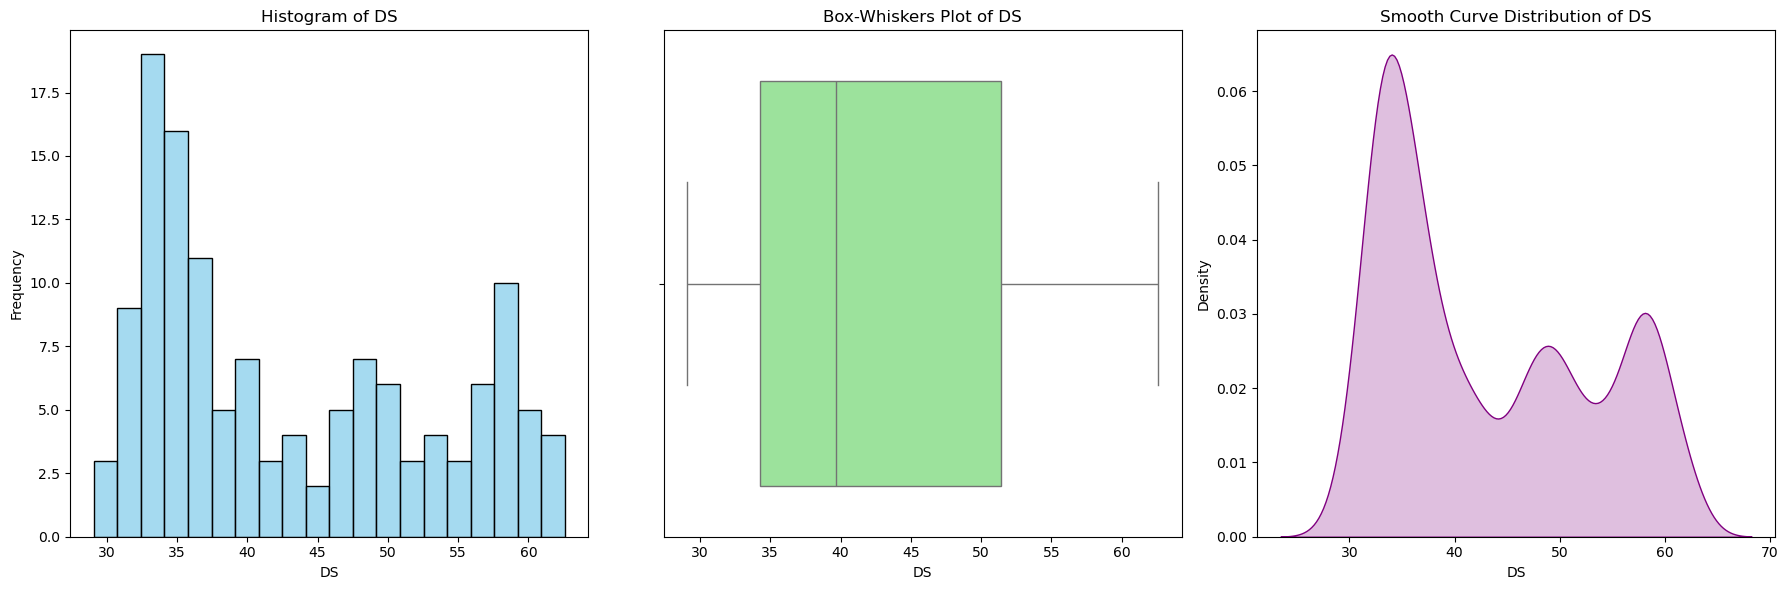

In [172]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Extract "ds" column
ds_values = case_A_PM["ds"]

# Create a figure with multiple subplots
plt.figure(figsize=(18, 6))

# Histogram
plt.subplot(1, 3, 1)
sns.histplot(ds_values, bins=20, kde=False, color="skyblue", edgecolor="black")
plt.title("Histogram of DS")
plt.xlabel("DS")
plt.ylabel("Frequency")

# Box-Whiskers Plot
plt.subplot(1, 3, 2)
sns.boxplot(x=ds_values, color="lightgreen")
plt.title("Box-Whiskers Plot of DS")
plt.xlabel("DS")

# Smooth Curve Distribution (Kernel Density Estimate)
plt.subplot(1, 3, 3)
sns.kdeplot(ds_values, fill=True, color="purple", bw_adjust=0.5)
plt.title("Smooth Curve Distribution of DS")
plt.xlabel("DS")
plt.ylabel("Density")

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

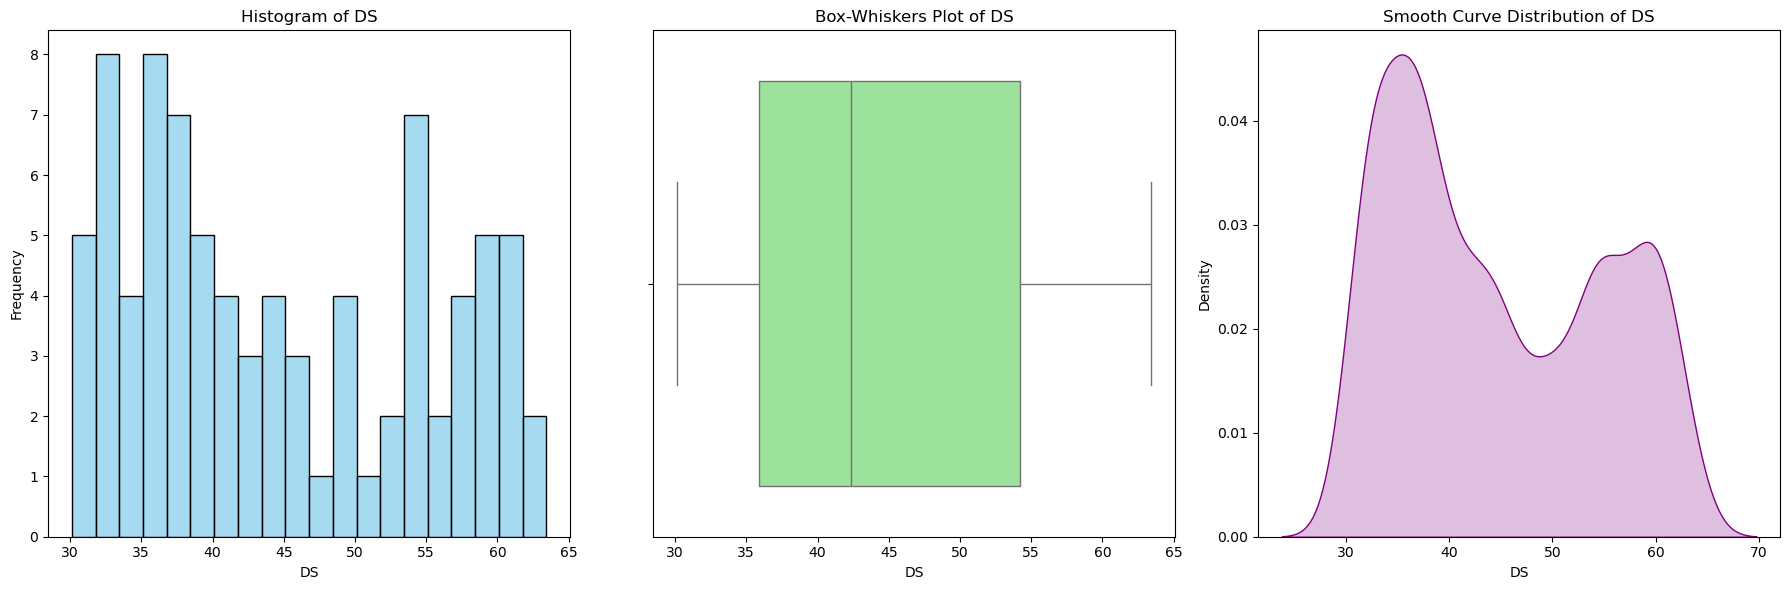

In [173]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Extract "ds" column
ds_values = case_B_PM["ds"]

# Create a figure with multiple subplots
plt.figure(figsize=(18, 6))

# Histogram
plt.subplot(1, 3, 1)
sns.histplot(ds_values, bins=20, kde=False, color="skyblue", edgecolor="black")
plt.title("Histogram of DS")
plt.xlabel("DS")
plt.ylabel("Frequency")

# Box-Whiskers Plot
plt.subplot(1, 3, 2)
sns.boxplot(x=ds_values, color="lightgreen")
plt.title("Box-Whiskers Plot of DS")
plt.xlabel("DS")

# Smooth Curve Distribution (Kernel Density Estimate)
plt.subplot(1, 3, 3)
sns.kdeplot(ds_values, fill=True, color="purple", bw_adjust=0.5)
plt.title("Smooth Curve Distribution of DS")
plt.xlabel("DS")
plt.ylabel("Density")

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

In [180]:
test_normality(case_A_PM["ds"])

{'shapiro_statistic': 0.8937554435262555, 'p_value': 3.0337958109607086e-08}

In [181]:
test_normality(case_B_PM["ds"])

{'shapiro_statistic': 0.9146989777703624, 'p_value': 3.577622946600653e-05}

both case A and B are not normal so we gonna proceed with non-parametric test

In [183]:
non_parametric_statistics(case_A_PM["ds"], case_B_PM["ds"])

{'u_statistic': 5001.0,
 'u_p_value': 0.22569264615581575,
 'ks_statistic': 0.12337662337662338,
 'ks_p_value': 0.38075304805274834}

# analysis for 943

# analysis for 961